# [Transformer Pipeline](https://huggingface.co/docs/transformers/main_classes/pipelines)

## [주요 파라미터](https://huggingface.co/docs/transformers/main_classes/pipelines#transformers.pipeline)

- `task`: The task defining which pipeline will be returned.
  - "text-generation", "audio-classification", "image-to-text" 등
- `model`: The model that will be used by the pipeline to make predictions.
- `config(optional)`: The configuration that will be used by the pipeline to instantiate the model.
- `tokenizer(optional)`: The tokenizer that will be used by the pipeline to encode data for the model.

## [Pipeline 내부 프로세스](https://huggingface.co/learn/nlp-course/ko/chapter2/2?fw=pt)
- 파이프라인은 전처리(preprocessing), 모델로 입력 전달 및 후처리(postprocessing)의 3단계를 한번에 실행합니다.

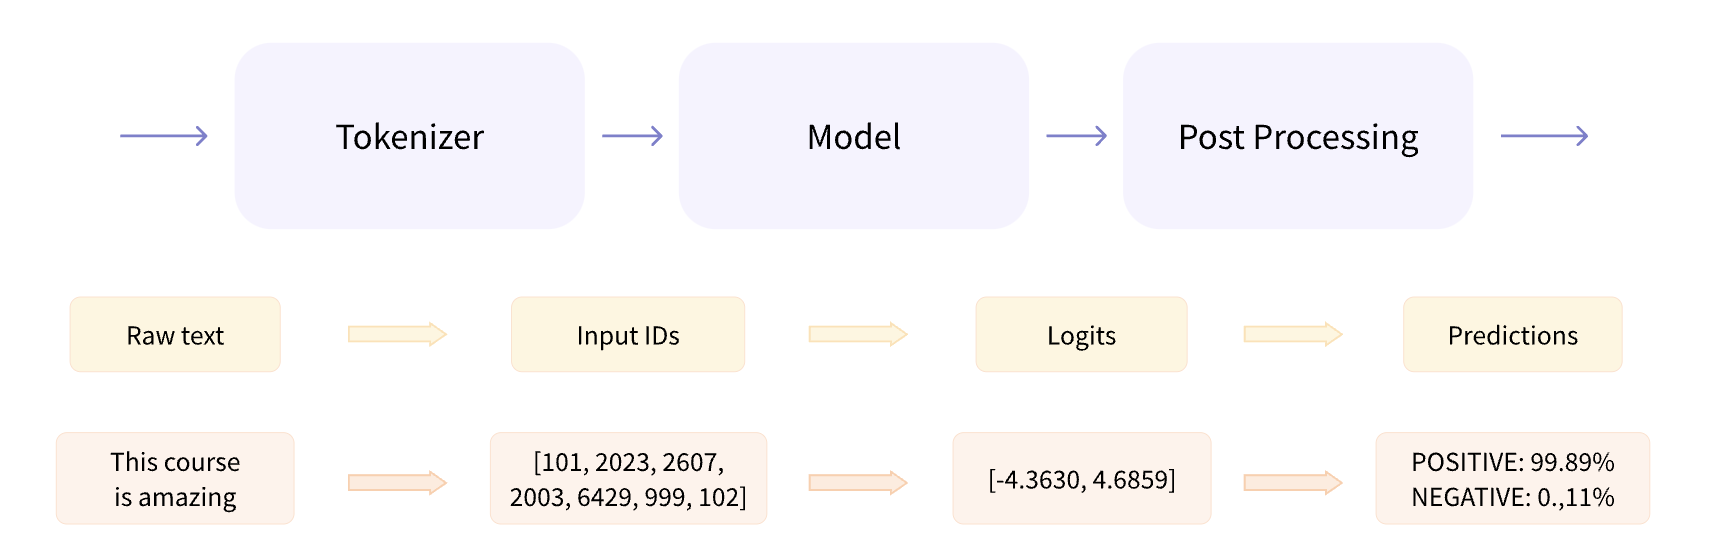

### Tokenizer

#### 단어 기반 토큰화 (Word-based Tokenization)
- 가장 먼저 생각할 수 있는 토큰화(tokenization) 형태는 단어기반 (word-based) 입니다.
- 일반적으로 몇 가지 규칙만 가지고도 설정 및 사용이 매우 쉽고, 종종 괜찮은 결과를 얻을 수 있습니다.

예를 들어, 아래 그림에서의 토큰화 과정은 원시 텍스트를 단어로 나누고 각각에 대한 숫자 표현을 찾는 것입니다:

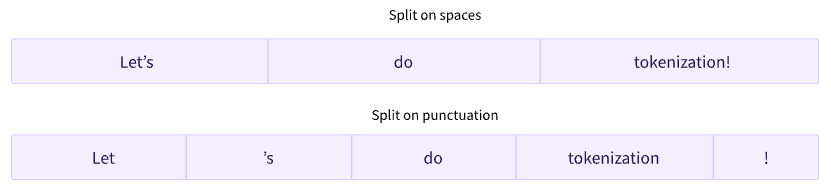

In [1]:
# 단어 기반 토큰화의 간단한 예시
# split() 메서드를 사용하여 공백을 기준으로 문장을 단어 단위로 분리
tokenized_text = "Jim Henson was a puppeteer".split()
print("토큰화된 결과:", tokenized_text)
print(f"토큰 개수: {len(tokenized_text)}개")

토큰화된 결과: ['Jim', 'Henson', 'was', 'a', 'puppeteer']
토큰 개수: 5개


단어기반 토크나이저로 특정 언어를 완전히 커버하려면, 해당 언어의 모든 단어에 대한 식별자가 필요하고, 이는 엄청난 양의 토큰을 생성합니다.
- 예를 들어, 영어에는 500,000개 이상의 단어가 있으므로 개별 단어에 대한 input ID(입력 식별자)로의 매핑을 구성하기 위해서 그만큼의 식별자들을 감당해야 합니다.
- 게다가, "dog"와 같은 단어는 "dogs"와 같은 단어와 다르게 표현되며, 모델은 처음에는 "dog"와 "dogs"가 유사한 단어들인지 파악하기 어렵습니다.
- 따라서, 두 단어를 관련이 없는 것으로 인식합니다. 이는 "run"과 "running"과 같은 다른 유사한 단어들도 마찬가지 입니다.

마지막으로, 어휘집(vocabulary)에 없는 단어를 표현하기 위해 사용자 정의 토큰이 필요합니다.
- 이는 "unknown" 토큰으로 알려져 있으며, 종종 "[UNK]" 또는 ""로 표시됩니다.
- 토크나이저가 이러한 "unknown" 토큰을 많이 생성한다는 것은 토크나이저가 해당 단어의 합당한 표현(sensible representation)을 찾을 수 없고, 그 과정에서 정보를 잃어버린다는 뜻이므로 나쁜 징조입니다.
- 어휘집(vocabulary)을 만들 때, 토크나이저가 이러한 "unknown" 토큰들을 최대한 적게 출력하게끔 하는 것이 목표가 되어야 합니다.

#### 토크나이저 로딩 및 저장
- 토크나이저를 로드하고 저장하는 것은 모델의 경우처럼 간단합니다.
- 실제로, 모델을 로드하고 저장할 때와 같이, `from_pretrained()` 및 `save_pretrained()` 메서드(method)를 그대로 사용합니다.
- 이들 메서드(method)들은 토크나이저(모델의 아키텍처와 약간 비슷함)와 어휘집(vocabulary, 모델의 가중치(weights)와 비슷함)에서 사용하는 알고리즘을 로드하거나 저장합니다.

`AutoModel` 클래스와 유사하게 `AutoTokenizer` 클래스는 라이브러리에서 체크포인트 이름에 해당하는 토크나이저 클래스를 가져옵니다. 라이브러리 내의 다른 모든 체크포인트와 함께 직접 사용할 수 있습니다.

In [2]:
# Hugging Face Transformers의 AutoTokenizer를 사용하여 BERT 토크나이저 로드
# bert-base-cased: 대소문자를 구분하는 BERT 모델의 기본 토크나이저
from transformers import AutoTokenizer

# 사전 훈련된 BERT 모델의 토크나이저를 불러오기
# "bert-base-cased"는 12개 레이어, 768개 히든 유닛, 12개 어텐션 헤드를 가진 모델
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")
print("BERT 토크나이저가 성공적으로 로드되었습니다.")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

c:\dev\course\course_Huggingface\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Playdata\.cache\huggingface\hub\models--bert-base-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

BERT 토크나이저가 성공적으로 로드되었습니다.


In [3]:
# 토크나이저를 사용하여 텍스트를 처리
# 이 메서드는 내부적으로 다음 단계들을 수행합니다:
# 1. 토큰화 (Tokenization): 텍스트를 토큰으로 분리
# 2. 입력 ID 변환: 각 토큰을 숫자 ID로 변환
# 3. 어텐션 마스크 생성: 실제 토큰과 패딩 토큰을 구분
result = tokenizer("Using a Transformer network is simple")
print("토크나이저 결과:")
print(result)

토크나이저 결과:
{'input_ids': [101, 7993, 170, 13809, 23763, 2443, 1110, 3014, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1]}


토크나이저를 저장하는 것은 모델을 저장하는 것과 동일합니다.

In [4]:
# 토크나이저를 로컬 폴더에 저장
# 저장되는 파일들:
# - tokenizer_config.json: 토크나이저 설정
# - vocab.txt: 어휘집 파일
# - special_tokens_map.json: 특수 토큰 매핑
tokenizer.save_pretrained("saving_folder")
print("토크나이저가 'saving_folder'에 저장되었습니다.")

토크나이저가 'saving_folder'에 저장되었습니다.


#### 인코딩 (Encoding)
- 텍스트를 숫자로 변환하는(translating text to numbers) 과정을 인코딩(encoding) 이라고 합니다.
- 인코딩(encoding)은 토큰화와 입력 식별자(input IDs)로의 변환이라는 2단계 프로세스로 수행됩니다.
  - 토큰화 프로세스는 토크나이저의 `tokenize()` 메서드에 의해 수행됩니다.
  - 각 토큰들의 입력 식별자(input IDs)로의 변환은 `convert_tokens_to_ids()` 메서드에 의해 처리됩니다.

In [5]:
from transformers import AutoTokenizer

# BERT 토크나이저 다시 로드 (이미 로드되어 있지만 예시를 위해)
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")

sequence = "Using a Transformer network is simple"

# 1단계: 토큰화 - 텍스트를 서브워드 토큰으로 분리
# BERT는 WordPiece 토큰화를 사용하여 단어를 더 작은 단위로 분해
tokens = tokenizer.tokenize(sequence)
print("토큰화 결과:", tokens)
print(f"토큰 개수: {len(tokens)}개")
print("주목: 'Transformer'가 'Trans'와 '##former'로 분리되었습니다.")

토큰화 결과: ['Using', 'a', 'Trans', '##former', 'network', 'is', 'simple']
토큰 개수: 7개
주목: 'Transformer'가 'Trans'와 '##former'로 분리되었습니다.


In [6]:
# 2단계: 토큰을 입력 ID로 변환
# 각 토큰을 모델이 이해할 수 있는 숫자 ID로 변환
# 이 ID들은 토크나이저의 어휘집(vocabulary)에서의 인덱스
ids = tokenizer.convert_tokens_to_ids(tokens)
print("입력 ID:", ids)
print("토큰 -> ID 매핑:")
for token, id in zip(tokens, ids):
    print(f"  '{token}' -> {id}")

입력 ID: [7993, 170, 13809, 23763, 2443, 1110, 3014]
토큰 -> ID 매핑:
  'Using' -> 7993
  'a' -> 170
  'Trans' -> 13809
  '##former' -> 23763
  'network' -> 2443
  'is' -> 1110
  'simple' -> 3014


#### 디코딩 (Decoding)
- 디코딩(decoding)은 반대 방향으로 진행됩니다. 변환된 입력 식별자(input IDs)를 이용해서 어휘집(vocabulary)에서 해당 문자열을 찾습니다. 이것은 다음과 같이 `decode()` 메서드를 사용하여 수행할 수 있습니다.

In [7]:
# 디코딩: 입력 ID를 다시 텍스트로 변환
# 모델의 출력 ID를 사람이 읽을 수 있는 텍스트로 복원
decoded_string = tokenizer.decode(ids)

print("디코딩 결과:", decoded_string)
print("원본 텍스트와 동일한지 확인:", decoded_string == sequence)

디코딩 결과: Using a Transformer network is simple
원본 텍스트와 동일한지 확인: True


### Model
- 이 섹션에서는 모델을 생성하고 사용하는 방법을 자세히 살펴보겠습니다. 이를 위해, 우리는 지정된 체크포인트(checkpoint)를 바탕으로 모델을 인스턴스화할 때 편리한 `AutoModel` 클래스를 사용할 것입니다.
- `AutoModel` 클래스와 이와 관련된 모든 항목들은 실제로 라이브러리에서 사용할 수 있는 다양한 모델에 대한 단순한 래퍼(wrapper)입니다. 당신이 선택한 체크포인트(checkpoint)에 적합한 모델 아키텍처(model architecture)를 자동으로 추측한 다음 이 아키텍처로 모델을 인스턴스화할 수 있으므로 영리한 래퍼(wrapper)라고 볼 수 있습니다.

#### 트랜스포머 모델 생성하기
- 해당모델은 학습을 하지 않은 상태이다.
- 즉, 사용을 하기 위해서는 충분한 학습을 한 후에 사용을 해야 한다.

In [8]:
from transformers import AutoConfig, AutoModel

# 방법 1: 설정을 먼저 로드한 후 모델 생성
# 이 방법은 모델 아키텍처만 생성하고 사전 훈련된 가중치는 로드하지 않음
# (따라서 모델을 사용하기 전에 추가 학습이 필요)
print("BERT 모델 설정을 로드하는 중...")
config = AutoConfig.from_pretrained("bert-base-cased")
print(f"모델 설정: {config.architectures}")

# 설정을 바탕으로 랜덤 가중치를 가진 새로운 모델 생성
print("새로운 모델 인스턴스를 생성하는 중...")
model = AutoModel.from_config(config)
print("모델 생성 완료 (랜덤 가중치)")
print(f"모델 파라미터 수: {model.num_parameters():,}개")

BERT 모델 설정을 로드하는 중...
모델 설정: ['BertForMaskedLM']
새로운 모델 인스턴스를 생성하는 중...
모델 생성 완료 (랜덤 가중치)
모델 파라미터 수: 108,310,272개


- 이 설정(configuration) 객체에는 모델을 빌드하는데 필요한 많은 속성이 포함되어 있습니다:
  - `hidden_size` 속성은 hidden_states 벡터의 크기를 정의하고
  - `num_hidden_layers` 는 Transformer 모델의 계층(layers) 수를 정의합니다.

In [9]:
# 모델 설정 정보 확인
# 이 설정은 모델의 아키텍처를 정의하는 모든 하이퍼파라미터를 포함
print("BERT 모델 설정 정보:")
print("=" * 50)
print(f"모델 타입: {config.model_type}")
print(f"은닉층 크기 (Hidden Size): {config.hidden_size}")
print(f"은닉층 개수 (Number of Hidden Layers): {config.num_hidden_layers}")
print(f"어텐션 헤드 개수 (Number of Attention Heads): {config.num_attention_heads}")
print(f"중간층 크기 (Intermediate Size): {config.intermediate_size}")
print(f"최대 위치 임베딩 (Max Position Embeddings): {config.max_position_embeddings}")
print(f"어휘집 크기 (Vocabulary Size): {config.vocab_size}")
print("=" * 50)
config

BERT 모델 설정 정보:
모델 타입: bert
은닉층 크기 (Hidden Size): 768
은닉층 개수 (Number of Hidden Layers): 12
어텐션 헤드 개수 (Number of Attention Heads): 12
중간층 크기 (Intermediate Size): 3072
최대 위치 임베딩 (Max Position Embeddings): 512
어휘집 크기 (Vocabulary Size): 28996


BertConfig {
  "add_cross_attention": false,
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "eos_token_id": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "tie_word_embeddings": true,
  "transformers_version": "5.5.3",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 28996
}

#### 모델 생성하기

- Tokenizer

In [10]:
from transformers import AutoTokenizer

# DistilBERT 모델을 사용한 감정 분석 예제
# "distilbert-base-uncased-finetuned-sst-2-english"는 Stanford Sentiment Treebank 데이터셋으로
# 파인튜닝된 DistilBERT 모델로, 영화 리뷰의 감정(긍정/부정)을 분류
checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
print(f"모델 체크포인트: {checkpoint}")
print("감정 분석용 토크나이저를 로드하는 중...")
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
print("토크나이저 로드 완료")

모델 체크포인트: distilbert-base-uncased-finetuned-sst-2-english
감정 분석용 토크나이저를 로드하는 중...


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

c:\dev\course\course_Huggingface\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Playdata\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

토크나이저 로드 완료


In [11]:
# 배치 처리를 위한 여러 텍스트 입력
# 감정 분석을 위한 예시 문장들: 하나는 긍정적, 하나는 부정적
raw_inputs = [
    "I've been waiting for a HuggingFace course my whole life.",  # 긍정적 문장
    "I hate this so much!",  # 부정적 문장
]

# 토크나이저 배치 처리 옵션들:
# - padding=True: 배치 내 모든 시퀀스를 같은 길이로 맞춤 (짧은 것은 패딩 추가)
# - truncation=True: 최대 길이를 초과하는 시퀀스를 자름
# - return_tensors="pt": PyTorch 텐서 형태로 반환
print("입력 텍스트를 토큰화하는 중...")
inputs = tokenizer(raw_inputs, padding=True, truncation=True, return_tensors="pt")
print("\n토큰화 결과:")
print(f"Input IDs 형태: {inputs['input_ids'].shape}")
print(f"Attention Mask 형태: {inputs['attention_mask'].shape}")
print("\n상세 결과:")
print(inputs)

입력 텍스트를 토큰화하는 중...

토큰화 결과:
Input IDs 형태: torch.Size([2, 16])
Attention Mask 형태: torch.Size([2, 16])

상세 결과:
{'input_ids': tensor([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,
          2607,  2026,  2878,  2166,  1012,   102],
        [  101,  1045,  5223,  2023,  2061,  2172,   999,   102,     0,     0,
             0,     0,     0,     0,     0,     0]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]])}


- Model

In [12]:
from transformers import AutoModel

# 방법 2: 사전 훈련된 가중치와 함께 모델 로드
# 이 방법은 실제 사용 가능한 모델을 로드 (추천 방법)
checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
print(f"사전 훈련된 모델을 로드하는 중: {checkpoint}")
model = AutoModel.from_pretrained(checkpoint)
print("모델 로드 완료")
print(f"모델 파라미터 수: {model.num_parameters():,}개")
print("주의: 이 모델은 기본 특징 추출만 수행하며, 분류 헤드가 포함되지 않았습니다.")

사전 훈련된 모델을 로드하는 중: distilbert-base-uncased-finetuned-sst-2-english


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
pre_classifier.weight | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


모델 로드 완료
모델 파라미터 수: 66,362,880개
주의: 이 모델은 기본 특징 추출만 수행하며, 분류 헤드가 포함되지 않았습니다.


Transformer 모듈의 벡터 출력은 일반적으로 규모가 큽니다. 일반적으로 세 가지 차원이 있습니다:
- `배치 크기(Batch size)`: 한 번에 처리되는 시퀀스(sequence)의 개수(위의 예제에서는 2개).
- `시퀀스 길이(Sequence length)`: 시퀀스 숫자 표현의 길이(이 예에서는 16).
- `은닉 크기(Hidden size)`: 각 모델 입력의 벡터 차원.

In [13]:
# 모델에 토큰화된 입력을 전달하여 추론 수행
# **inputs는 딕셔너리를 키워드 인수로 언패킹
# (input_ids=inputs['input_ids'], attention_mask=inputs['attention_mask']와 동일)
print("모델 추론 실행 중...")
outputs = model(**inputs)

# 출력 텐서의 형태 확인
# last_hidden_state: 마지막 히든 레이어의 출력
# 형태: [batch_size, sequence_length, hidden_size]
print(f"출력 텐서 형태: {outputs.last_hidden_state.shape}")
print("형태 해석:")
print(f"  - 배치 크기 (Batch size): {outputs.last_hidden_state.shape[0]}개 문장")
print(f"  - 시퀀스 길이 (Sequence length): {outputs.last_hidden_state.shape[1]}개 토큰")
print(f"  - 히든 크기 (Hidden size): {outputs.last_hidden_state.shape[2]}차원 벡터")

모델 추론 실행 중...
출력 텐서 형태: torch.Size([2, 16, 768])
형태 해석:
  - 배치 크기 (Batch size): 2개 문장
  - 시퀀스 길이 (Sequence length): 16개 토큰
  - 히든 크기 (Hidden size): 768차원 벡터


이번에 사용한 예시에서는 시퀀스 분류 헤드(sequence classification head)가 포함되어 있는 모델이 필요합니다(문장을 긍정 또는 부정으로 분류하기 위해서).

따라서 실제로 AutoModel 클래스를 사용하지 않고 대신 `AutoModelForSequenceClassification`를 사용합니다.

In [14]:
# 감정 분석을 위한 시퀀스 분류 모델 로드
# AutoModelForSequenceClassification은 분류 헤드가 포함된 모델
# 이 모델은 텍스트를 입력받아 클래스별 점수(logits)를 출력
from transformers import AutoModelForSequenceClassification

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
print("시퀀스 분류 모델을 로드하는 중...")
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)
print(f"분류 클래스 수: {model.config.num_labels}개")
print(f"레이블 매핑: {model.config.id2label}")

# 모델 추론 실행
print("\n감정 분석 추론 실행 중...")
outputs = model(**inputs)
print("추론 완료")

시퀀스 분류 모델을 로드하는 중...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

분류 클래스 수: 2개
레이블 매핑: {0: 'NEGATIVE', 1: 'POSITIVE'}

감정 분석 추론 실행 중...
추론 완료


두 개의 문장과 두 개의 레이블만 있기 때문에, 모델에서 얻은 결과의 모양(shape)은 2 x 2입니다.

In [15]:
# 분류 모델의 출력 형태 확인
# logits: 각 클래스에 대한 원시 점수 (소프트맥스 적용 전)
# 형태: [batch_size, num_labels]
print(f"Logits 형태: {outputs.logits.shape}")
print("형태 해석:")
print(f"  - 배치 크기: {outputs.logits.shape[0]}개 문장")
print(f"  - 클래스 수: {outputs.logits.shape[1]}개 (NEGATIVE, POSITIVE)")

Logits 형태: torch.Size([2, 2])
형태 해석:
  - 배치 크기: 2개 문장
  - 클래스 수: 2개 (NEGATIVE, POSITIVE)


### Post Processing

In [16]:
# 원시 logits 값 확인
# 이 값들은 아직 확률로 변환되지 않은 상태
print("원시 Logits 값:")
print(outputs.logits)
print("\n각 문장별 logits:")
for i, sentence in enumerate(raw_inputs):
    print(f"문장 {i+1}: '{sentence}'")
    print(f"  NEGATIVE: {outputs.logits[i][0]:.4f}")
    print(f"  POSITIVE: {outputs.logits[i][1]:.4f}")
    if outputs.logits[i][1] > outputs.logits[i][0]:
        print("  → 예측: POSITIVE")
    else:
        print("  → 예측: NEGATIVE")
    print()

원시 Logits 값:
tensor([[-1.5607,  1.6123],
        [ 4.1692, -3.3464]], grad_fn=<AddmmBackward0>)

각 문장별 logits:
문장 1: 'I've been waiting for a HuggingFace course my whole life.'
  NEGATIVE: -1.5607
  POSITIVE: 1.6123
  → 예측: POSITIVE

문장 2: 'I hate this so much!'
  NEGATIVE: 4.1692
  POSITIVE: -3.3464
  → 예측: NEGATIVE



- 모델 추론(inference)

In [17]:
import torch

# 후처리: Logits를 확률로 변환
# 소프트맥스 함수를 사용하여 logits를 0~1 사이의 확률 값으로 변환
# dim=-1은 마지막 차원(클래스 차원)에 대해 소프트맥스 적용
print("Logits를 확률로 변환 중...")
predictions = torch.nn.functional.softmax(outputs.logits, dim=-1)
print("확률 변환 결과:")
print(predictions)

print("\n각 문장별 확률:")
for i, sentence in enumerate(raw_inputs):
    print(f"문장 {i+1}: '{sentence}'")
    neg_prob = predictions[i][0].item()
    pos_prob = predictions[i][1].item()
    print(f"  NEGATIVE: {neg_prob:.4f} ({neg_prob*100:.2f}%)")
    print(f"  POSITIVE: {pos_prob:.4f} ({pos_prob*100:.2f}%)")
    predicted_class = "POSITIVE" if pos_prob > neg_prob else "NEGATIVE"
    print(f"  최종 예측: {predicted_class}")
    print()

Logits를 확률로 변환 중...
확률 변환 결과:
tensor([[4.0195e-02, 9.5980e-01],
        [9.9946e-01, 5.4418e-04]], grad_fn=<SoftmaxBackward0>)

각 문장별 확률:
문장 1: 'I've been waiting for a HuggingFace course my whole life.'
  NEGATIVE: 0.0402 (4.02%)
  POSITIVE: 0.9598 (95.98%)
  최종 예측: POSITIVE

문장 2: 'I hate this so much!'
  NEGATIVE: 0.9995 (99.95%)
  POSITIVE: 0.0005 (0.05%)
  최종 예측: NEGATIVE



In [18]:
# 모델의 레이블 매핑 정보 확인
# id2label: 숫자 ID를 레이블 이름으로 매핑하는 딕셔너리
# 0 -> "NEGATIVE", 1 -> "POSITIVE"
print("모델의 레이블 매핑:")
print(model.config.id2label)
print("\n역방향 매핑 (label2id):")
print(model.config.label2id)

모델의 레이블 매핑:
{0: 'NEGATIVE', 1: 'POSITIVE'}

역방향 매핑 (label2id):
{'NEGATIVE': 0, 'POSITIVE': 1}


## 최종 감정 분석 결과 요약

모델의 예측 결과를 종합하면 다음과 같습니다:

### 문장별 감정 분석 결과:
- **첫 번째 문장**: `"I've been waiting for a HuggingFace course my whole life."`
  - NEGATIVE: 4.02% 
  - **POSITIVE: 95.98%**
  - **예측**: 긍정적 감정

- **두 번째 문장**: `"I hate this so much!"`
  - **NEGATIVE: 99.95%**
  - POSITIVE: 0.05%
  - **예측**: 부정적 감정

### 분석 정확도:
두 문장 모두 인간의 직관과 일치하는 정확한 감정 분류 결과를 보여줍니다.
- 첫 번째 문장: 기대감과 흥미를 표현하는 긍정적 문장
- 두 번째 문장: 강한 혐오감을 표현하는 부정적 문장

## [사용가능한 파이프라인](https://fallenangel13th.tistory.com/16)

Transformers 라이브러리는 다양한 NLP 작업을 위한 사전 구성된 파이프라인을 제공합니다. 
각 파이프라인은 **토큰화 → 모델 추론 → 후처리**의 전체 과정을 자동으로 처리하여 사용자가 쉽게 최신 NLP 모델을 활용할 수 있게 합니다.

### 주요 파이프라인 종류:
1. **`feature-extraction`**: 텍스트의 벡터 표현 추출
2. **`fill-mask`**: 마스크된 단어 예측 (BERT 스타일)
3. **`ner`**: 개체명 인식 (Named Entity Recognition)
4. **`question-answering`**: 문맥 기반 질의 응답
5. **`sentiment-analysis`**: 감정 분석 (긍정/부정)
6. **`summarization`**: 텍스트 요약
7. **`text-generation`**: 텍스트 생성
8. **`translation`**: 언어 번역
9. **`zero-shot-classification`**: 제로샷 분류

### 파이프라인 사용 시 주의사항:
- **모델 선택**: 작업에 특화된 파인튜닝된 모델을 사용하는 것이 중요
- **성능 vs 속도**: 더 큰 모델일수록 성능이 좋지만 처리 속도는 느림
- **언어 지원**: 한국어 작업 시 한국어 특화 모델 사용 권장 (예: KLUE 시리즈)

### `feature-extraction`
- 특징 추출 (텍스트에 대한 벡터 표현 추출)

```python
from transformers import pipeline
import numpy as np

pipe = pipeline("feature-extraction")
result = pipe("hello")
print(result)
```

In [19]:
# Feature Extraction (특징 추출) 파이프라인
# 텍스트를 고차원 벡터 표현으로 변환하는 작업
# 주로 텍스트 유사도 계산, 클러스터링, 검색 등에 활용
from transformers import pipeline
import numpy as np

print("Feature Extraction 파이프라인 생성 중...")
print("기본 모델: distilbert-base-cased")
pipe = pipeline(task="feature-extraction")

# 단어 "hello"를 벡터로 변환
print("\n텍스트 'hello'를 벡터로 변환 중...")
result = pipe("hello")
print(f"결과 형태: {np.array(result).shape}")
print("형태 해석: [배치_크기, 시퀀스_길이, 특징_차원]")

No model was supplied, defaulted to distilbert/distilbert-base-cased and revision 6ea8117.
Using a pipeline without specifying a model name and revision in production is not recommended.


Feature Extraction 파이프라인 생성 중...
기본 모델: distilbert-base-cased


config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

c:\dev\course\course_Huggingface\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Playdata\.cache\huggingface\hub\models--distilbert--distilbert-base-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/263M [00:00<?, ?B/s]

...

DistilBertModel LOAD REPORT from: distilbert/distilbert-base-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


텍스트 'hello'를 벡터로 변환 중...
결과 형태: (1, 3, 768)
형태 해석: [배치_크기, 시퀀스_길이, 특징_차원]


In [20]:
# 특징 추출 결과 확인
# 결과는 3차원 리스트 형태 [배치, 토큰, 특징]
print("특징 벡터 결과 (처음 5개 차원만 표시):")
print("=" * 50)

# numpy 배열로 변환하여 쉽게 다루기
result_array = np.array(result)
print(f"전체 형태: {result_array.shape}")

# 첫 번째 배치, 첫 번째 토큰의 처음 10개 특징값만 출력
if len(result_array.shape) == 3:
    first_token_features = result_array[0, 0, :10]  # 처음 10개 특징만
    print(f"첫 번째 토큰의 특징벡터 (처음 10개): {first_token_features}")
    print(f"특징벡터 전체 차원: {result_array.shape[-1]}")
else:
    print("결과 형태가 예상과 다릅니다:")
    print(result)

특징 벡터 결과 (처음 5개 차원만 표시):
전체 형태: (1, 3, 768)
첫 번째 토큰의 특징벡터 (처음 10개): [ 0.33866099  0.20652895  0.13104627 -0.23268345 -0.31125033 -0.08519075
  0.21013889 -0.0597147   0.01169238 -1.25196934]
특징벡터 전체 차원: 768


### [fill-mask](https://huggingface.co/docs/transformers/tasks/masked_language_modeling)
- 마스크 채우기

```python
from transformers import pipeline
import numpy as np

pipe = pipeline("fill-mask")
result = pipe("A Man is <mask>", top_k=3) #top_k는 가장 확률이 높은 3개 출력
print(result)


[{'score': 0.11967816203832626,
  'token': 23632,
  'token_str': ' Missing',
  'sequence': 'A Man is Missing'},
 {'score': 0.10868901759386063,
  'token': 8912,
  'token_str': ' Born',
  'sequence': 'A Man is Born'},
 {'score': 0.05237989127635956,
  'token': 9088,
  'token_str': ' Dead',
  'sequence': 'A Man is Dead'}]

```

In [21]:
# Fill-Mask (마스크 채우기) 작업을 위한 예시 텍스트
# <mask> 토큰이 있는 위치에 적절한 단어를 예측하는 작업
# 이는 BERT와 같은 마스크된 언어 모델의 대표적인 활용 사례

text = "The Milky Way is a <mask> galaxy."
print(f"입력 텍스트: {text}")
print("목표: <mask> 위치에 들어갈 적절한 단어 찾기")

입력 텍스트: The Milky Way is a <mask> galaxy.
목표: <mask> 위치에 들어갈 적절한 단어 찾기


In [22]:
# Fill-Mask 파이프라인 생성
# DistilRoBERTa 모델을 사용하여 마스크된 단어 예측
from transformers import pipeline

print("Fill-Mask 파이프라인 생성 중...")
print("사용 모델: distilbert/distilroberta-base (RoBERTa 기반)")
mask_filler = pipeline(task="fill-mask", model="distilbert/distilroberta-base")

print(f"\n분석할 텍스트: {text}")
print("상위 3개 예측 결과를 요청합니다...")

# top_k=3: 가장 확률이 높은 상위 3개 단어 후보를 반환
result = mask_filler(text, top_k=3)
print("\n마스크 채우기 결과:")
for i, prediction in enumerate(result, 1):
    print(f"{i}. '{prediction['token_str']}' - 확률: {prediction['score']:.4f}")
    print(f"   완성된 문장: {prediction['sequence']}")

result

Fill-Mask 파이프라인 생성 중...
사용 모델: distilbert/distilroberta-base (RoBERTa 기반)


Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



분석할 텍스트: The Milky Way is a <mask> galaxy.
상위 3개 예측 결과를 요청합니다...

마스크 채우기 결과:
1. ' spiral' - 확률: 0.6469
   완성된 문장: The Milky Way is a spiral galaxy.
2. ' dwarf' - 확률: 0.1454
   완성된 문장: The Milky Way is a dwarf galaxy.
3. ' massive' - 확률: 0.0368
   완성된 문장: The Milky Way is a massive galaxy.


[{'score': 0.6469371318817139,
  'token': 21300,
  'token_str': ' spiral',
  'sequence': 'The Milky Way is a spiral galaxy.'},
 {'score': 0.1454411745071411,
  'token': 30794,
  'token_str': ' dwarf',
  'sequence': 'The Milky Way is a dwarf galaxy.'},
 {'score': 0.036787249147892,
  'token': 2232,
  'token_str': ' massive',
  'sequence': 'The Milky Way is a massive galaxy.'}]

### [ner](https://huggingface.co/docs/transformers/tasks/token_classification)
- 개체명 인식(NER, Named Entity Recognition)은 입력 텍스트에서 어느 부분이 사람, 위치 또는 조직과 같은 개체명에 해당하는지 식별하는 작업
- 파이프라인 생성 함수에서 `grouped_entities=True` → 파이프라인이 동일한 엔티티에 해당하는 문장의 부분(토큰 혹은 단어)들을 그룹화하도록 함

```python
from transformers import pipeline
import numpy as np

pipe = pipeline("ner", grouped_entities=True) #grouped_entities=True 같은 개체 그룹화
result = pipe("Dokdo is a unique territory of Korea.")

#출력
print(result)
[{'entity_group': 'LOC',
  'score': 0.9633191,
  'word': 'Dokdo',
  'start': 0,
  'end': 5},
 {'entity_group': 'LOC',
  'score': 0.9983676,
  'word': 'Korea',
  'start': 31,
  'end': 36}]
```

In [23]:
# NER(Named Entity Recognition) 작업을 위한 예시 텍스트
# 여러 유형의 개체명(조직, 지명 등)이 포함된 문장
text = "The Golden State Warriors are an American professional basketball team based in San Francisco."
print(f"분석할 텍스트: {text}")
print("목표: 사람명(PER), 조직명(ORG), 지명(LOC) 등의 개체명 식별")


분석할 텍스트: The Golden State Warriors are an American professional basketball team based in San Francisco.
목표: 사람명(PER), 조직명(ORG), 지명(LOC) 등의 개체명 식별


In [27]:
# NER (Named Entity Recognition) 파이프라인 생성
# 주의: 이 예제는 파인튜닝되지 않은 모델을 사용하므로 정확한 결과를 기대하기 어려움
from transformers import pipeline

print("NER 파이프라인 생성 중...")
print("주의: distilbert-base-uncased는 NER 작업으로 파인튜닝되지 않은 모델입니다.")
print("실제 사용 시에는 NER 전용 모델 (예: dslim/bert-base-NER)을 사용하는 것이 좋습니다.")

# grouped_entities=True: 같은 개체에 속하는 연속된 토큰들을 하나로 그룹화
classifier = pipeline(task="ner", 
                     model="distilbert/distilbert-base-uncased")

print(f"\n개체명 인식 실행 중...")
result = classifier(text)
print("결과:")
if result:
    for entity in result:
        print(f"- {entity['word']}: {entity['entity']} (신뢰도: {entity['score']:.4f})")
else:
    print("인식된 개체명이 없습니다 (모델이 NER 작업으로 파인튜닝되지 않았기 때문)")

result

NER 파이프라인 생성 중...
주의: distilbert-base-uncased는 NER 작업으로 파인튜닝되지 않은 모델입니다.
실제 사용 시에는 NER 전용 모델 (예: dslim/bert-base-NER)을 사용하는 것이 좋습니다.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForTokenClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



개체명 인식 실행 중...
결과:
- the: LABEL_1 (신뢰도: 0.7323)
- golden: LABEL_1 (신뢰도: 0.7087)
- state: LABEL_1 (신뢰도: 0.5964)
- warriors: LABEL_1 (신뢰도: 0.5946)
- are: LABEL_1 (신뢰도: 0.6165)
- an: LABEL_1 (신뢰도: 0.6617)
- american: LABEL_1 (신뢰도: 0.6971)
- professional: LABEL_1 (신뢰도: 0.7755)
- basketball: LABEL_1 (신뢰도: 0.6963)
- team: LABEL_1 (신뢰도: 0.7144)
- based: LABEL_1 (신뢰도: 0.6944)
- in: LABEL_1 (신뢰도: 0.6470)
- san: LABEL_1 (신뢰도: 0.6919)
- francisco: LABEL_1 (신뢰도: 0.6987)
- .: LABEL_1 (신뢰도: 0.5442)


[{'entity': 'LABEL_1',
  'score': np.float32(0.73227817),
  'index': 1,
  'word': 'the',
  'start': 0,
  'end': 3},
 {'entity': 'LABEL_1',
  'score': np.float32(0.7086869),
  'index': 2,
  'word': 'golden',
  'start': 4,
  'end': 10},
 {'entity': 'LABEL_1',
  'score': np.float32(0.5963636),
  'index': 3,
  'word': 'state',
  'start': 11,
  'end': 16},
 {'entity': 'LABEL_1',
  'score': np.float32(0.5945983),
  'index': 4,
  'word': 'warriors',
  'start': 17,
  'end': 25},
 {'entity': 'LABEL_1',
  'score': np.float32(0.6165154),
  'index': 5,
  'word': 'are',
  'start': 26,
  'end': 29},
 {'entity': 'LABEL_1',
  'score': np.float32(0.66174376),
  'index': 6,
  'word': 'an',
  'start': 30,
  'end': 32},
 {'entity': 'LABEL_1',
  'score': np.float32(0.69710183),
  'index': 7,
  'word': 'american',
  'start': 33,
  'end': 41},
 {'entity': 'LABEL_1',
  'score': np.float32(0.77548563),
  'index': 8,
  'word': 'professional',
  'start': 42,
  'end': 54},
 {'entity': 'LABEL_1',
  'score': np.flo

### [sentiment-analysis](https://huggingface.co/docs/transformers/tasks/sequence_classification#inference)
- 감정 분석

```python
from transformers import pipeline

pipe = pipeline("sentiment-analysis")
pipe(['I am King in the world'])

#출력
[{'label': 'POSITIVE', 'score': 0.999794065952301}]
```

In [33]:
# 감정 분석을 위한 예시 텍스트 (영화 리뷰)
# 긍정적인 감정이 담긴 문장으로 감정 분석 테스트
text = "This was a masterpiece. Not completely faithful to the books, but enthralling from beginning to end. Might be my favorite of the three."
print(f"분석할 텍스트: {text}")
print("목표: 텍스트에 담긴 감정(긍정/부정) 분류")


분석할 텍스트: This was a masterpiece. Not completely faithful to the books, but enthralling from beginning to end. Might be my favorite of the three.
목표: 텍스트에 담긴 감정(긍정/부정) 분류


In [34]:
# Sentiment Analysis (감정 분석) 파이프라인
# 주의: 이 모델은 감정 분석으로 파인튜닝되지 않았으므로 정확한 결과를 기대하기 어려움
from transformers import pipeline

print("Sentiment Analysis 파이프라인 생성 중...")
print("주의: distilbert-base-uncased는 감정 분석으로 파인튜닝되지 않은 모델입니다.")
print("실제 사용 시에는 감정 분석 전용 모델을 사용하는 것이 좋습니다.")
print("(예: cardiffnlp/twitter-roberta-base-sentiment-latest)")

classifier = pipeline(task="sentiment-analysis", 
                     model="distilbert/distilbert-base-uncased")

print(f"\n감정 분석 실행 중...")
result = classifier(text)

print("결과:")
if result:
    for item in result:
        print(f"감정: {item['label']}")
        print(f"신뢰도: {item['score']:.4f}")
else:
    print("분석 결과가 없습니다.")

result

Sentiment Analysis 파이프라인 생성 중...
주의: distilbert-base-uncased는 감정 분석으로 파인튜닝되지 않은 모델입니다.
실제 사용 시에는 감정 분석 전용 모델을 사용하는 것이 좋습니다.
(예: cardiffnlp/twitter-roberta-base-sentiment-latest)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



감정 분석 실행 중...
결과:
감정: LABEL_0
신뢰도: 0.5664


[{'label': 'LABEL_0', 'score': 0.5664427280426025}]

### [text-generation](https://huggingface.co/docs/transformers/tasks/language_modeling)
- 텍스트 생성

```python
from transformers import pipeline

pipe = pipeline("text-generation", model="skt/kogpt2-base-v2", max_length=30)
pipe("나는 오늘 저녁에 밥을 먹고")

#출력
[{'generated_text': '나는 오늘 저녁에 밥을 먹고\n어디로 가는지부터 고민의 연속이다.\n그렇다면 나흘 동안 어디를 가고 그리고 어디로 가야 할까요?\n'}]
```

In [43]:
from transformers import pipeline

pipe = pipeline(task="text-generation", model="skt/kogpt2-base-v2", max_length=30)
pipe("너의 이름은 ")

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: skt/kogpt2-base-v2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'generated_text': "너의 이름은 )▁와▁접점하여▁'와칭'이라고▁부른다.\n이▁명칭은▁중국어를▁포함하여▁전▁세계▁각지에서▁쓰이고▁있는데,▁주로▁중국어와▁일본어,▁스페인어,▁독일어,▁러시아어,▁터키어,▁페르시아어,▁이탈리아어,▁폴란드어,▁아랍어,▁루마니아어,▁이탈리아어,"}]

### `zero-shot-classification`
- 제로샷 분류

```python
from transformers import pipeline

classifier = pipeline("zero-shot-classification", model="hyunwoongko/kobart")
classifier(
    "개구리는 양서류이다.",
    candidate_labels=["교육", "정치", "사업"],
)

#출력
{'sequence': '개구리는 양서류이다.',
 'labels': ['사업', '정치', '교육'],
 'scores': [0.38976219296455383, 0.3134584426879883, 0.2967793345451355]}
```

In [39]:
from transformers import pipeline

classifier = pipeline(task="zero-shot-classification", model="hyunwoongko/kobart")
classifier(
    "개구리는 양서류이다.",
    candidate_labels=["교육", "정치", "사업"],
)

config.json: 0.00B [00:00, ?B/s]

c:\dev\course\course_Huggingface\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Playdata\.cache\huggingface\hub\models--hyunwoongko--kobart. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin:   0%|          | 0.00/496M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/261 [00:00<?, ?it/s]

BartForSequenceClassification LOAD REPORT from: hyunwoongko/kobart
Key                                 | Status  | 
------------------------------------+---------+-
classification_head.dense.weight    | MISSING | 
classification_head.out_proj.weight | MISSING | 
classification_head.out_proj.bias   | MISSING | 
classification_head.dense.bias      | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

model.safetensors:   0%|          | 0.00/495M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/109 [00:00<?, ?B/s]

Failed to determine 'entailment' label id from the label2id mapping in the model config. Setting to -1. Define a descriptive label2id mapping in the model config to ensure correct outputs.


{'sequence': '개구리는 양서류이다.',
 'labels': ['사업', '교육', '정치'],
 'scores': [0.4092618227005005, 0.30095842480659485, 0.28977975249290466]}